# Session 1: Basics of Python

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in []:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-01_keywords_identifiers.py`

In [2]:
"""
Session 1 · Example 1: keywords and identifiers
-----------------------------------------------
Shows the reserved words of the running Python version and tests a list of
candidate variable names against Python's naming rules.
Run:  python session-01_keywords_identifiers.py
"""
import keyword

# 1. Keywords: words with a fixed meaning that you can never use as names
print("Python has", len(keyword.kwlist), "keywords:")
for i in range(0, len(keyword.kwlist), 9):          # print 9 per line
    print("  ", ", ".join(keyword.kwlist[i:i + 9]))

# Soft keywords (match, case, type, _) are reserved only in certain places
print("Soft keywords:", keyword.softkwlist)

# 2. Identifier rules: start with a letter or _, then letters, digits or _,
#    no spaces or symbols, not a keyword. Python is case-sensitive.
def check_name(name):
    """Return (is_valid, reason) for a proposed variable name."""
    if keyword.iskeyword(name):
        return False, "is a keyword"
    if not name.isidentifier():
        if name[:1].isdigit():
            return False, "starts with a digit"
        return False, "contains a space or symbol"
    if name.startswith("__") and name.endswith("__"):
        return True, "valid, but dunder names are reserved for Python itself"
    return True, "valid"

candidates = ["student_name", "Marks2025", "_total", "2nd_place", "first name",
              "class", "price$", "StudentName", "__init__", "cgpa"]
print("\nName check")
for c in candidates:
    ok, why = check_name(c)
    print(f"  {c!r:16} {'OK ' if ok else 'BAD'}  {why}")

# 3. Case sensitivity: three different variables
total, Total, TOTAL = 1, 2, 3
print("\ntotal, Total, TOTAL ->", total, Total, TOTAL)

Python has 35 keywords:
   False, None, True, and, as, assert, async, await, break
   class, continue, def, del, elif, else, except, finally, for
   from, global, if, import, in, is, lambda, nonlocal, not
   or, pass, raise, return, try, while, with, yield
Soft keywords: ['_', 'case', 'match', 'type']

Name check
  'student_name'   OK   valid
  'Marks2025'      OK   valid
  '_total'         OK   valid
  '2nd_place'      BAD  starts with a digit
  'first name'     BAD  contains a space or symbol
  'class'          BAD  is a keyword
  'price$'         BAD  contains a space or symbol
  'StudentName'    OK   valid
  '__init__'       OK   valid, but dunder names are reserved for Python itself
  'cgpa'           OK   valid

total, Total, TOTAL -> 1 2 3


## Example: `session-01_statements_comments.py`

In [3]:
"""
Session 1 · Example 2: statements, comments and indentation
------------------------------------------------------------
Run:  python session-01_statements_comments.py
"""
# A comment starts with # and runs to the end of the line. Python ignores it.

# --- Simple statements: one per line (a ; joins two, but avoid it) ---
city = "Karachi"
population_m = 20.4          # inline comment: millions, rough figure for the demo
a = 1; b = 2                 # legal, but harder to read

# --- A long statement split over lines ---
# Implicit continuation inside (), [] or {} is the preferred style
fee_breakdown = [
    "tuition",
    "lab",
    "library",
]
total_fee = (45_000      # underscores make big numbers readable
             + 5_000
             + 1_500)
# Explicit continuation with a backslash also works, but breaks easily
message = "Fees for " + city + \
          " campus"

# --- Compound statements: a header ending in ':' and an indented block ---
def describe(fee):
    """Docstring: the first string in a function documents it."""
    if fee > 50_000:
        level = "high"           # 4 spaces = one level
    else:
        level = "normal"
    return level

print(message, "->", total_fee, describe(total_fee))
print("Items:", fee_breakdown, "| a + b =", a + b)
print("Docstring of describe():", describe.__doc__)

# --- Indentation errors are caught before the program runs ---
bad_code = "if True:\nprint('no indent')"
try:
    compile(bad_code, "<demo>", "exec")
except IndentationError as e:
    print("IndentationError:", e.msg, "on line", e.lineno)

mixed = "if True:\n    x = 1\n  y = 2"      # inconsistent dedent
try:
    compile(mixed, "<demo>", "exec")
except IndentationError as e:
    print("IndentationError:", e.msg, "on line", e.lineno)

Fees for Karachi campus -> 51500 high
Items: ['tuition', 'lab', 'library'] | a + b = 3
Docstring of describe(): Docstring: the first string in a function documents it.
IndentationError: expected an indented block after 'if' statement on line 1 on line 2
IndentationError: unindent does not match any outer indentation level on line 3


## Example: `session-01_variables.py`

In [4]:
"""
Session 1 · Example 3: variables, assignment and dynamic typing
---------------------------------------------------------------
Run:  python session-01_variables.py
"""
# 1. A variable is a name bound to an object
marks = 78
print("marks =", marks, "| type:", type(marks).__name__, "| isinstance int:", isinstance(marks, int))

# 2. Dynamic typing: the same name can later point to another type
marks = "seventy-eight"
print("marks =", marks, "| type:", type(marks).__name__)

# 3. Multiple assignment and unpacking
x = y = z = 0                         # one object, three names
name, age, cgpa = "Ayesha", 21, 3.62  # tuple unpacking
print("x, y, z =", x, y, z, "|", name, age, cgpa)

# 4. Swapping without a temporary variable
left, right = "tea", "coffee"
left, right = right, left
print("after swap:", left, right)

# 5. Augmented assignment
balance = 1_000
balance += 250        # balance = balance + 250
balance -= 100
balance *= 2
print("balance:", balance)

# 6. Names are labels, not boxes: two names can share one list
a = [1, 2, 3]
b = a                 # b is another label on the SAME list
b.append(4)
print("a:", a, "| a is b:", a is b)
c = a.copy()          # a new list
c.append(5)
print("a:", a, "| c:", c, "| a is c:", a is c)

# 7. Constants are a naming convention (ALL_CAPS); Python does not enforce them
GST_RATE = 0.18
price = 2_500
print(f"price with GST: Rs {price * (1 + GST_RATE):,.2f}")

# 8. del removes the name, not necessarily the object
temp = 42
del temp
print("'temp' still defined?", "temp" in dir())

# 9. Reading input safely (simulated here so the script runs unattended)
def ask(prompt, default):
    """Use input() in real programs; this demo returns a fixed answer."""
    print(prompt + default)
    return default

age_text = ask("Enter your age: ", "21")
age = int(age_text)               # input() always returns a str: convert it
print("Next year you will be", age + 1)

marks = 78 | type: int | isinstance int: True
marks = seventy-eight | type: str
x, y, z = 0 0 0 | Ayesha 21 3.62
after swap: coffee tea
balance: 2300
a: [1, 2, 3, 4] | a is b: True
a: [1, 2, 3, 4] | c: [1, 2, 3, 4, 5] | a is c: False
price with GST: Rs 2,950.00
'temp' still defined? False
Enter your age: 21
Next year you will be 22


## Example: `session-01_problem_bill_splitter.py`

In [5]:
"""
Session 1 · Real-life problem: the dinner bill splitter
-------------------------------------------------------
PROBLEM
Five friends eat at a restaurant in Karachi. The menu prices exclude tax.
Write a program that:
  1. stores each person's items in variables and lists,
  2. adds 16 % sales tax and a 10 % service charge (on the pre-tax subtotal),
  3. splits the shared starter equally,
  4. prints a neat receipt showing what each person owes, rounded to the
     nearest rupee, and checks that the shares add up to the total.

SOLUTION: only variables, arithmetic, lists, a loop and f-strings.
Run:  python session-01_problem_bill_splitter.py
"""
TAX_RATE = 0.16          # constants in ALL_CAPS
SERVICE_RATE = 0.10
shared_starter = 1_800   # one platter of fries and wings for the table

orders = {               # person -> list of (item, price)
    "Ali":    [("Chicken karahi (half)", 1_450), ("Mint lemonade", 350)],
    "Sana":   [("Daal makhni", 850), ("Garlic naan x2", 300)],
    "Bilal":  [("Beef burger", 1_250), ("Soft drink", 200)],
    "Hira":   [("Grilled fish", 1_900)],
    "Usman":  [("Club sandwich", 950), ("Cold coffee", 550)],
}

people = list(orders)                      # the dict keys, in order
starter_share = shared_starter / len(people)

print(f"{'Person':8} {'Food':>8} {'Starter':>8} {'Service':>8} {'Tax':>8} {'Owes':>8}")
print("-" * 54)
grand_total = 0
shares = {}
for person in people:
    food = sum(price for _, price in orders[person])
    subtotal = food + starter_share
    service = subtotal * SERVICE_RATE
    tax = subtotal * TAX_RATE
    owes = subtotal + service + tax
    shares[person] = round(owes)
    grand_total += owes
    print(f"{person:8} {food:8,.0f} {starter_share:8,.0f} {service:8,.0f} {tax:8,.0f} {round(owes):8,}")

print("-" * 54)
bill = (sum(p for items in orders.values() for _, p in items) + shared_starter) * (1 + TAX_RATE + SERVICE_RATE)
print(f"{'Bill':8} {'':35} {bill:8,.0f}")
diff = sum(shares.values()) - round(bill)
print(f"Sum of rounded shares = {sum(shares.values()):,} (difference Rs {diff:+d}, caused by rounding)")
biggest = max(shares, key=shares.get)
print(f"Highest share: {biggest} (Rs {shares[biggest]:,})")

# --- Optional chart: what makes up each share (stacked bars) ---
import matplotlib
matplotlib.use("Agg")                     # draw to a file, no window needed
import matplotlib.pyplot as plt

food = [sum(p for _, p in orders[x]) for x in people]
extra = [starter_share] * len(people)
serv = [(f + starter_share) * SERVICE_RATE for f in food]
taxes = [(f + starter_share) * TAX_RATE for f in food]
fig, ax = plt.subplots(figsize=(7, 3.6))
bottom = [0] * len(people)
for values, label, colour in [(food, "Food", "#FF6B1A"), (extra, "Starter share", "#FCD34D"),
                              (serv, "Service 10%", "#A78BFA"), (taxes, "Tax 16%", "#F43F5E")]:
    ax.bar(people, values, bottom=bottom, label=label, color=colour)
    bottom = [b + v for b, v in zip(bottom, values)]
for i, total in enumerate(bottom):
    ax.text(i, total + 40, f"Rs {round(total):,}", ha="center", fontsize=9)
ax.set_ylabel("Rupees"); ax.set_title("What each friend pays"); ax.set_ylim(0, max(bottom) * 1.15)
ax.legend(ncol=4, fontsize=8, loc="upper center")
fig.tight_layout(); fig.savefig("session-01_problem_bill_splitter.png", dpi=110)
print("Chart saved: session-01_problem_bill_splitter.png")

Person       Food  Starter  Service      Tax     Owes
------------------------------------------------------
Ali         1,800      360      216      346    2,722
Sana        1,150      360      151      242    1,903
Bilal       1,450      360      181      290    2,281
Hira        1,900      360      226      362    2,848
Usman       1,500      360      186      298    2,344
------------------------------------------------------
Bill                                           12,096
Sum of rounded shares = 12,098 (difference Rs +2, caused by rounding)
Highest share: Hira (Rs 2,848)


Chart saved: session-01_problem_bill_splitter.png


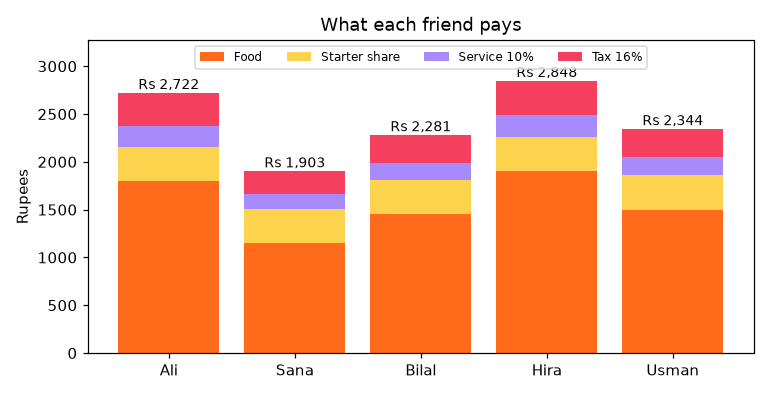

In [6]:
from IPython.display import Image, display
display(Image(filename='session-01_problem_bill_splitter.png'))  # chart saved by the cell above

## Example: `session-01_project_student_card.py`

In [7]:
"""
Session 1 · Mini project: student profile card generator
--------------------------------------------------------
Builds a formatted ID-style card from raw form data. Practises variables,
type conversion, string methods, f-string alignment and simple validation.
Run:  python session-01_project_student_card.py
"""
import keyword

WIDTH = 44   # inner width of the card

# Raw form data exactly as a web form would send it: everything is text
form = {
    "full_name": "  hamza   ali RAZA ",
    "roll_no": "ai-2026-0147",
    "program": "diploma in ai",
    "semester": "1",
    "cgpa": "3.456",
    "email": "Hamza.Raza@Example.com ",
    "username": "hamza_raza",
}

def clean_name(raw):
    """Collapse extra spaces and use Title Case."""
    return " ".join(raw.split()).title()

def valid_username(u):
    """A username follows the identifier rules from this session."""
    return u.isidentifier() and not keyword.iskeyword(u) and u.islower()

def line(text=""):
    return "| " + text.ljust(WIDTH) + " |"

# --- convert and clean ---
name = clean_name(form["full_name"])
roll = form["roll_no"].upper()
program = form["program"].title().replace(" In ", " in ").replace("Ai", "AI")
semester = int(form["semester"])
cgpa = round(float(form["cgpa"]), 2)
email = form["email"].strip().lower()
user = form["username"]

# --- validate ---
problems = []
if not 0 <= cgpa <= 4:
    problems.append("CGPA must be between 0 and 4")
if "@" not in email or email.startswith("@"):
    problems.append("email looks wrong")
if not valid_username(user):
    problems.append("username must be a lowercase identifier")

# --- print the card ---
border = "+" + "-" * (WIDTH + 2) + "+"
print(border)
print(line("STUDENT PROFILE".center(WIDTH)))
print(border)
print(line(f"{'Name':<10}: {name}"))
print(line(f"{'Roll no':<10}: {roll}"))
print(line(f"{'Program':<10}: {program}"))
print(line(f"{'Semester':<10}: {semester}"))
print(line(f"{'CGPA':<10}: {cgpa:.2f}  {'*' * round(cgpa)}"))
print(line(f"{'Email':<10}: {email}"))
print(line(f"{'Username':<10}: @{user}"))
print(border)
print("Validation:", "all fields OK" if not problems else "; ".join(problems))
print("Types after conversion:", {k: type(v).__name__ for k, v in
      {"name": name, "semester": semester, "cgpa": cgpa}.items()})

+----------------------------------------------+
|               STUDENT PROFILE                |
+----------------------------------------------+
| Name      : Hamza Ali Raza                   |
| Roll no   : AI-2026-0147                     |
| Program   : Diploma in AI                    |
| Semester  : 1                                |
| CGPA      : 3.46  ***                        |
| Email     : hamza.raza@example.com           |
| Username  : @hamza_raza                      |
+----------------------------------------------+
Validation: all fields OK
Types after conversion: {'name': 'str', 'semester': 'int', 'cgpa': 'float'}
